<a href="https://colab.research.google.com/github/ai6829071-lgtm/YOLO-Object-Detection/blob/main/Yolo_SubTasks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Subtask 1: Fire and Smoke Detection Using YOLO

In [ ]:
!pip install ultralytics roboflow opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 29.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 64.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [ultralytics]


In [ ]:
from ultralytics import YOLO
from roboflow import Roboflow
import cv2
import matplotlib.pyplot as plt
import os

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="jtCJlEUyRZ2yTvQ0IUw2")
project = rf.workspace("gfo-fc1de").project("fire-and-smoke-detector-yykya")
version = project.version(14)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to fire-and-smoke-detector-14 in yolo26:: 100%|██████████| 11204/11204 [00:01<00:00, 8134.91it/s]


In [ ]:
dataset.location

'/content/fire-and-smoke-detector-14'

## Dataset Description

In this task, we use the Fire and Smoke Detector dataset from Roboflow.

- Workspace: gfo-fc1de
- Project: fire-and-smoke-detector-yykya
- Version: 14
- Format: YOLO

The dataset contains labeled images for detecting fire and smoke.

YOLO format contains images and corresponding text annotation files. Each annotation includes the class ID and normalized bounding box coordinates.

The data.yaml file contains the dataset paths and class names.

The dataset is divided into three parts:

- Training: Used to train the model.
- Validation: Used to evaluate the model during training.
- Testing: Used to evaluate the model on unseen images.

In [ ]:
data_yaml = os.path.join(dataset.location, "data.yaml")

print("Dataset YAML Path:", data_yaml)

with open(data_yaml, "r") as file:
    print(file.read())

Dataset YAML Path: /content/fire-and-smoke-detector-14/data.yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 2
names: ['fire', 'smoke']

roboflow:
  workspace: gfo-fc1de
  project: fire-and-smoke-detector-yykya
  version: 14
  license: CC BY 4.0
  url: https://universe.roboflow.com/gfo-fc1de/fire-and-smoke-detector-yykya/dataset/14


## YOLO Model Training

We use YOLO26n, a nano-sized YOLO model, for custom object detection.

Object detection identifies objects and locates them using bounding boxes.

Training parameters:

- Model: YOLO26n
- Task: Detection
- Image Size: 640
- Epochs: 50

An epoch represents one complete pass through the training dataset.

Image size determines the resolution used during training.

During training, the model learns visual patterns and features that help it recognize fire and smoke.

In [ ]:
!yolo task = detect mode=train model=yolo26n.pt data={dataset.location}/data.yaml epochs=50 patience=10 imgsz=640 verbose=True

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/fire-and-smoke-detector-14/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimi

## Training Results Inspection

After training, YOLO saves the trained model weights and evaluation results.

The main output files are:

- best.pt: Contains the weights from the best-performing epoch.
- last.pt: Contains the weights from the final epoch.
- results.png: Shows training and validation performance over epochs.
- confusion_matrix.png: Shows the classification performance for each class.

Evaluation Metrics:

- Precision: Measures the proportion of correct positive predictions.
- Recall: Measures the proportion of actual objects detected by the model.
- mAP: Measures the overall object detection performance.

In [ ]:
results_dir = "/content/runs/detect/train"

print("Best Model:", os.path.exists(
    results_dir + "/weights/best.pt"
))

print("Last Model:", os.path.exists(
    results_dir + "/weights/last.pt"
))

Best Model: True
Last Model: True


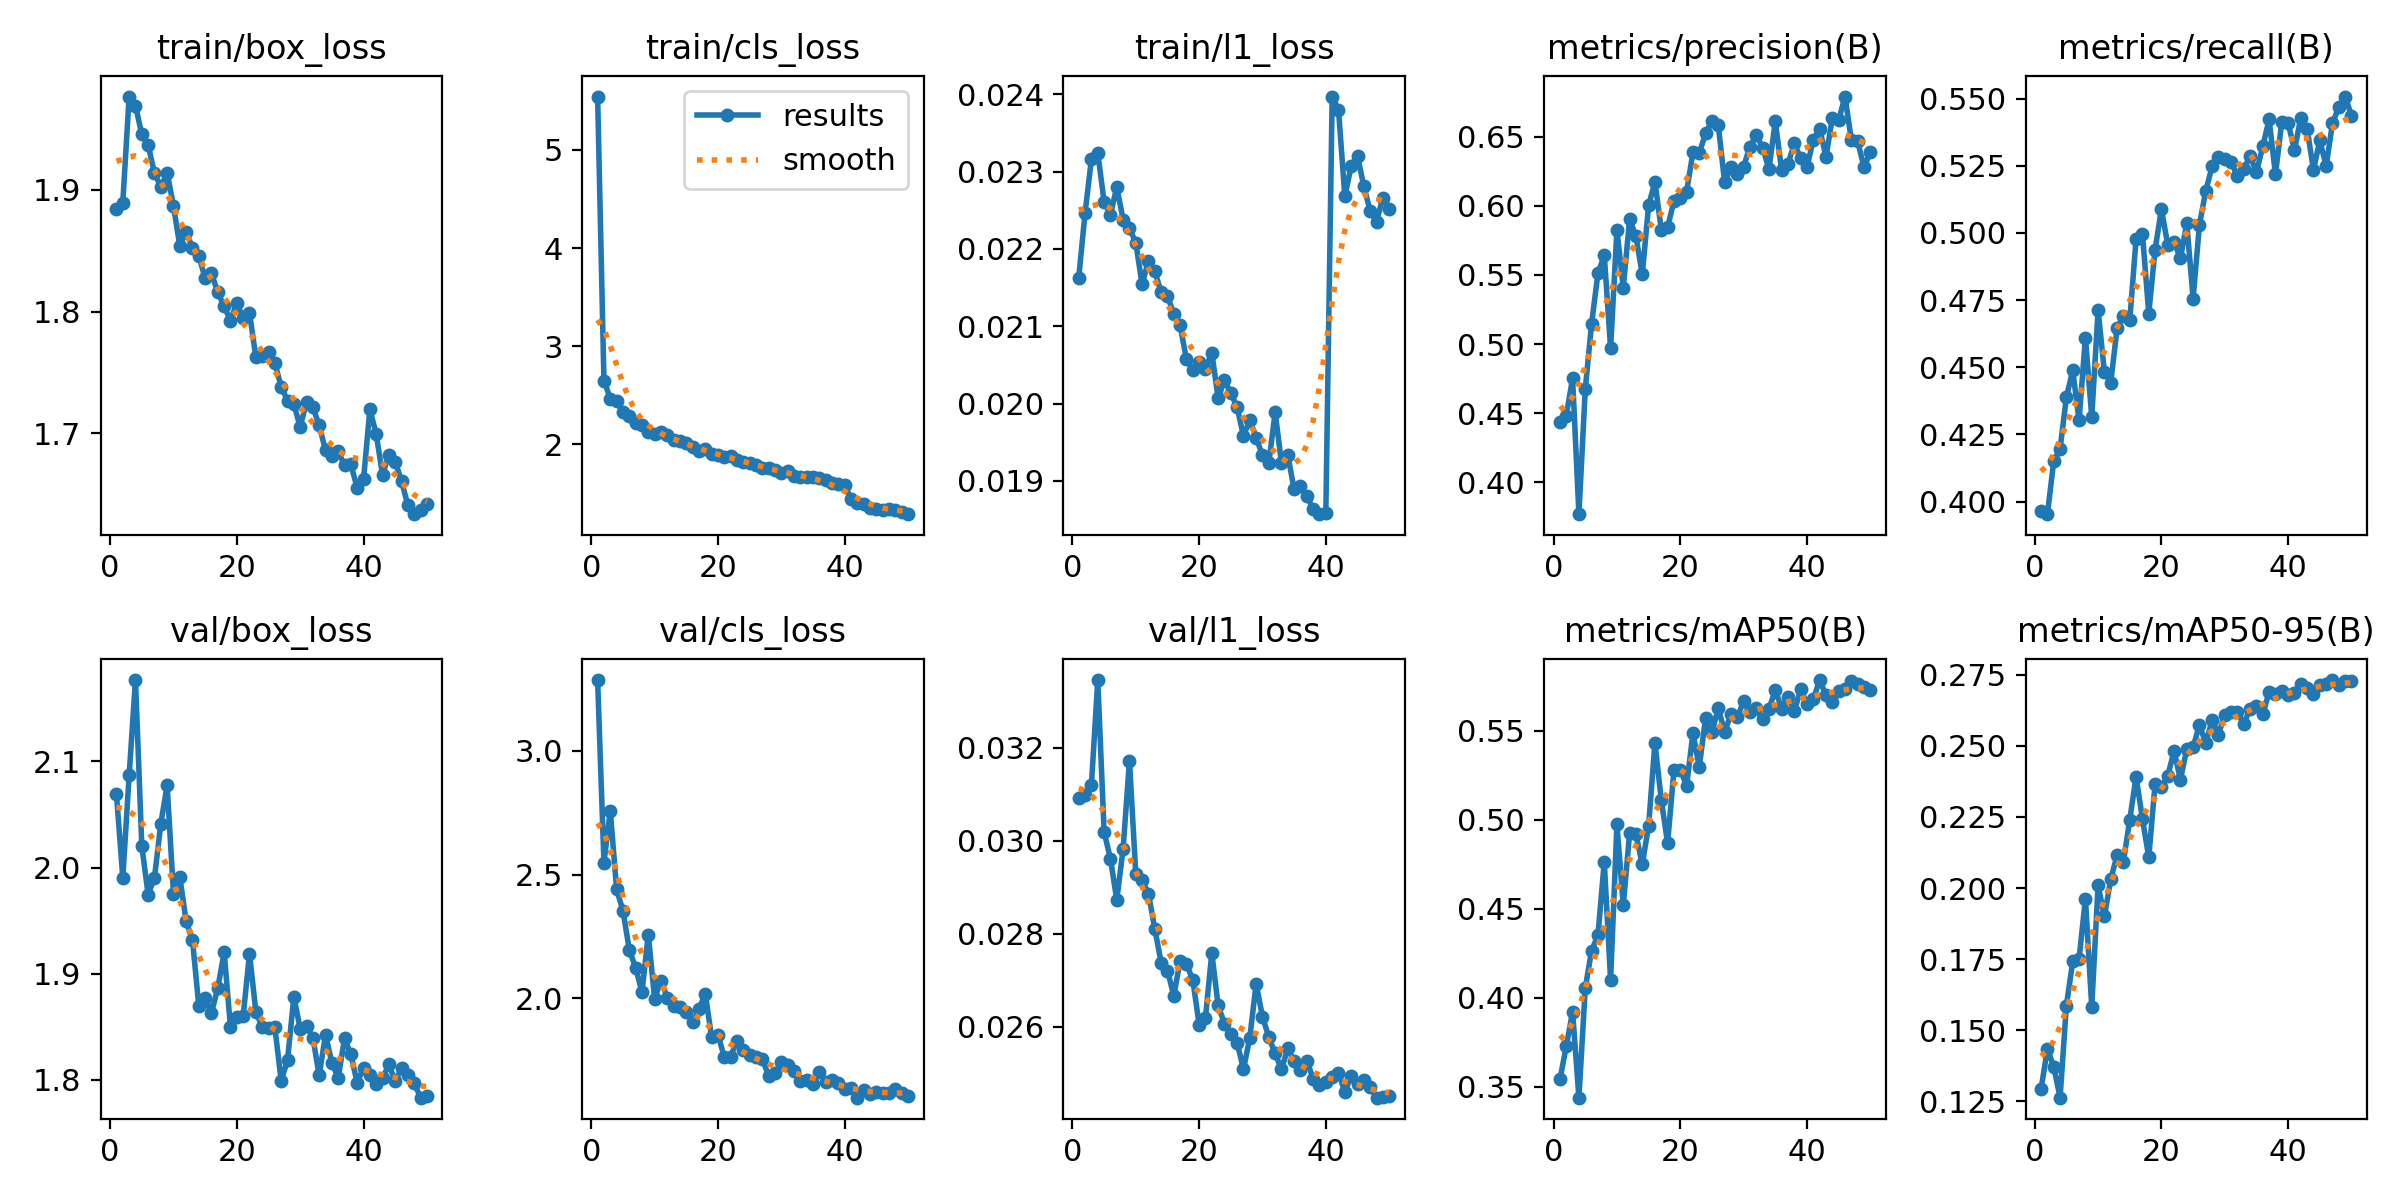

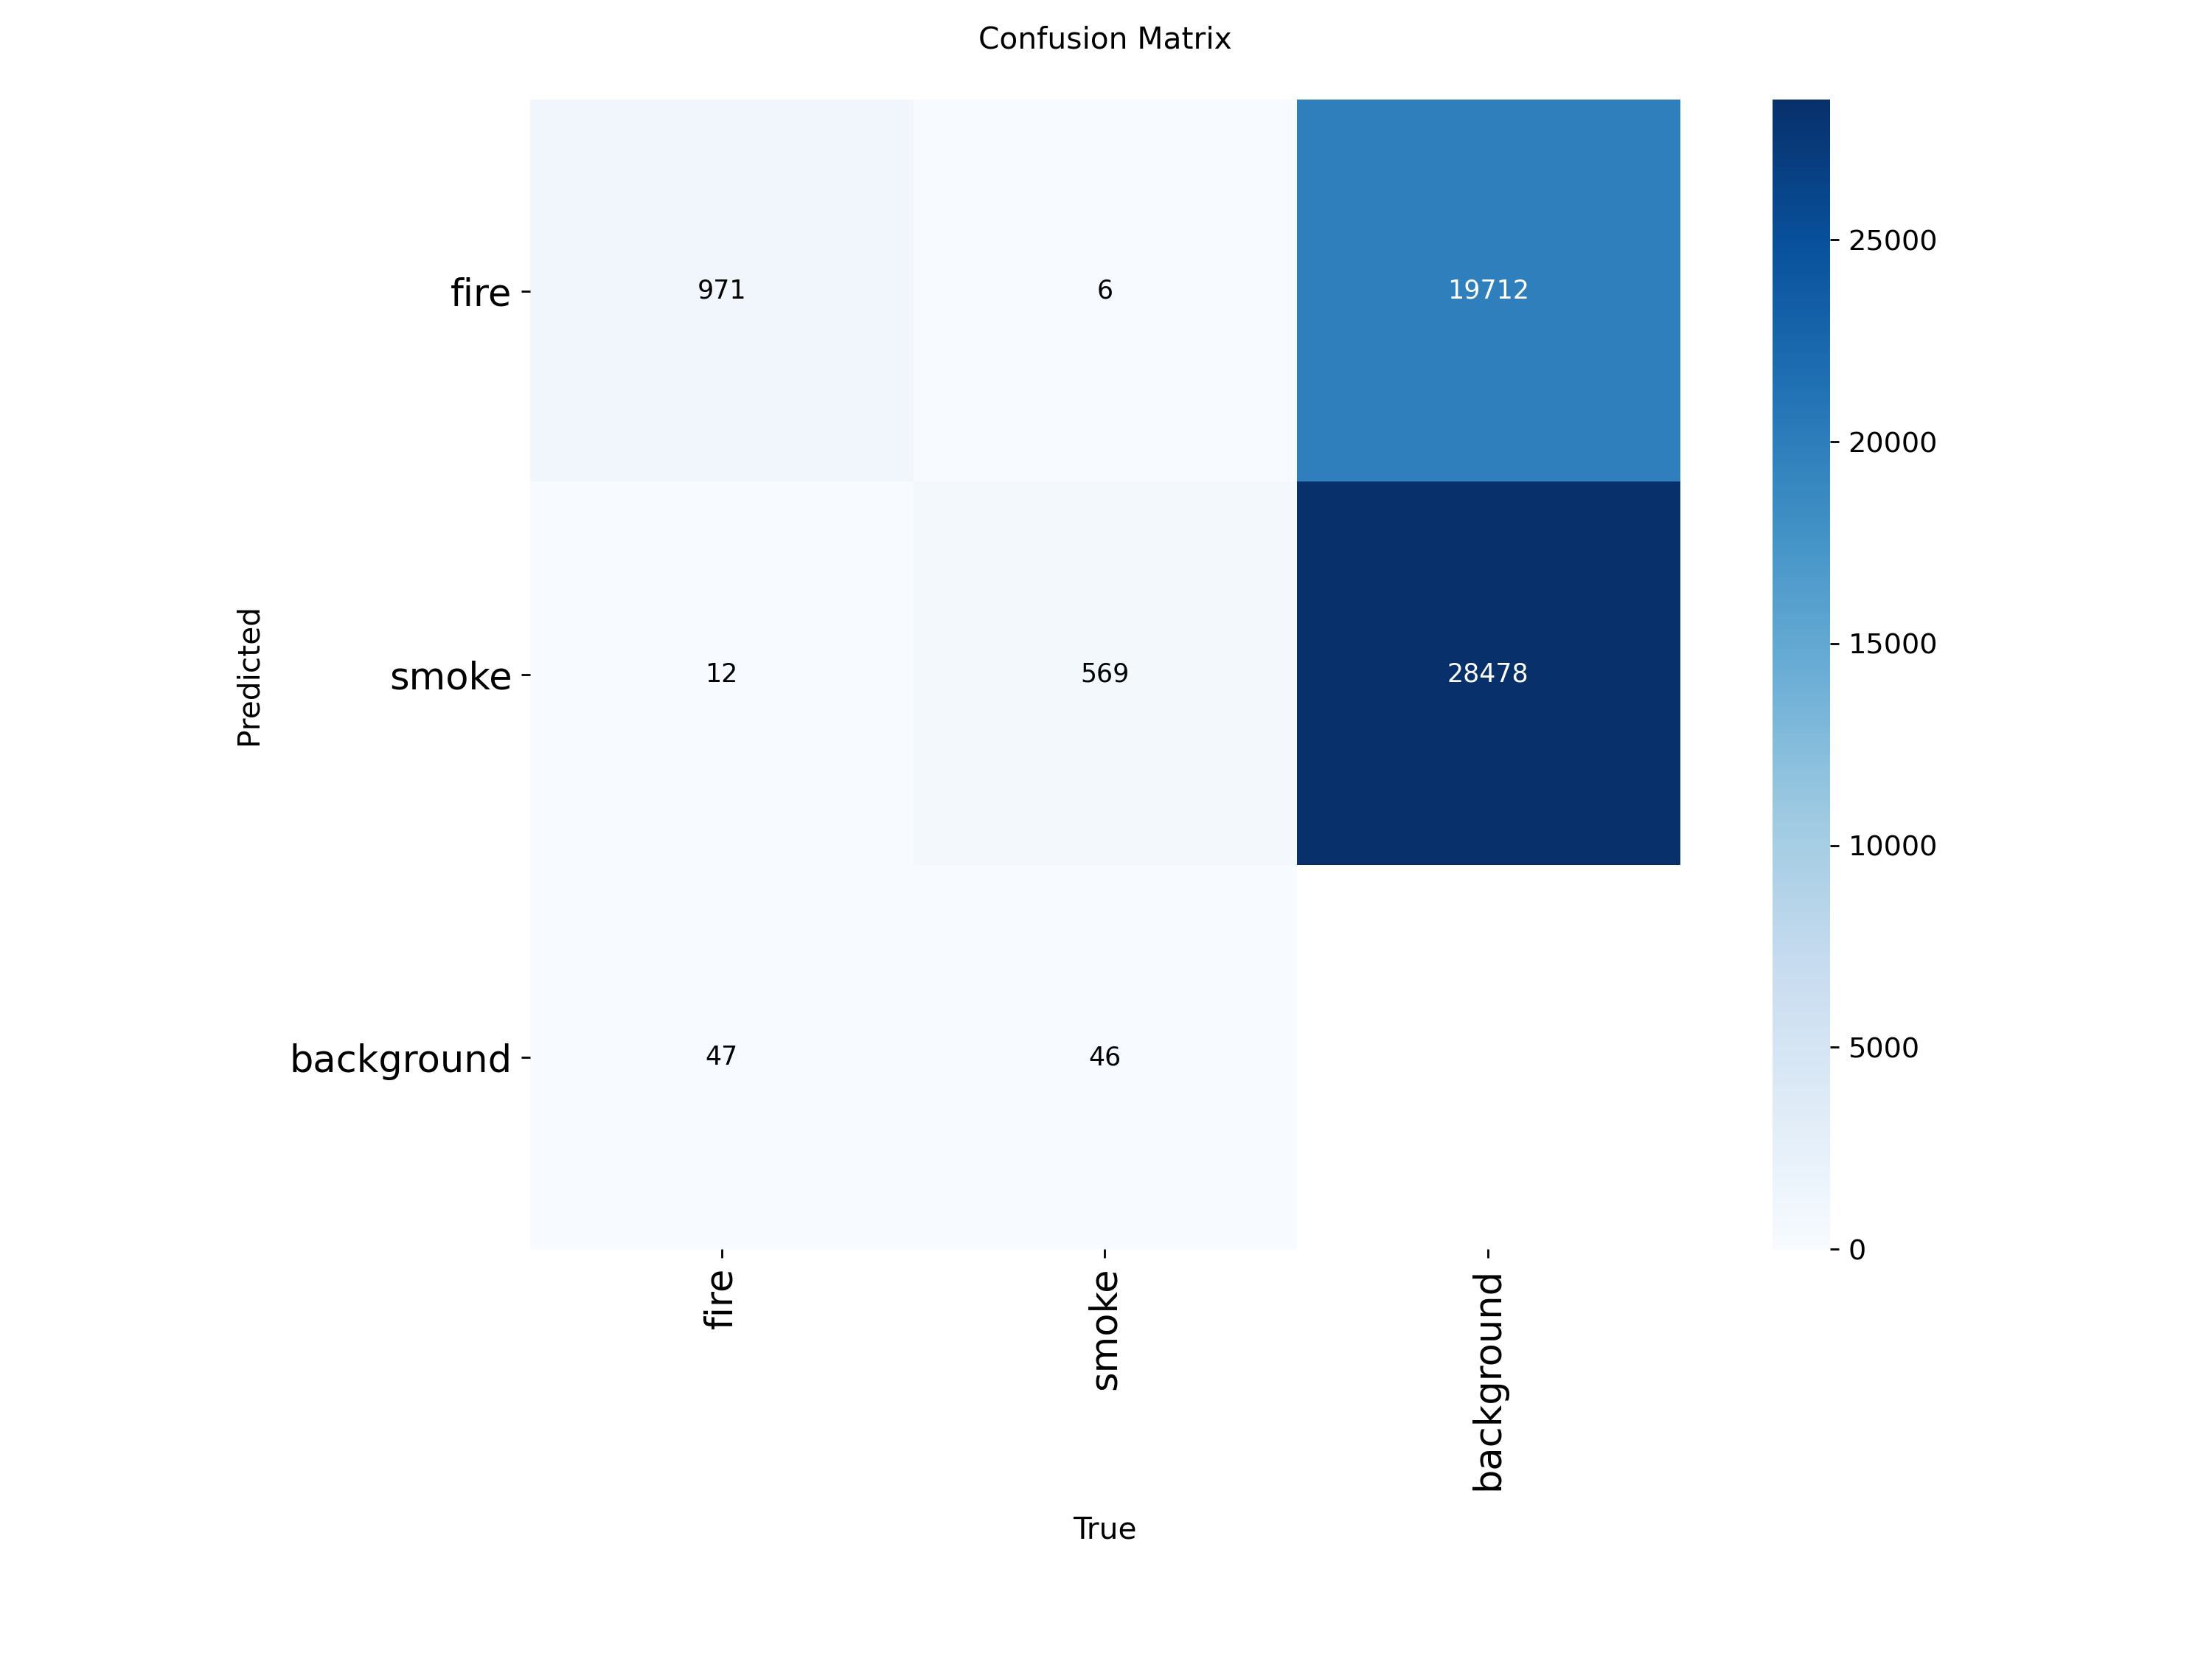

In [ ]:
from IPython.display import display, Image

display(Image(filename=results_dir + "/results.png"))

display(Image(filename=results_dir + "/confusion_matrix.png"))

In [ ]:
import pandas as pd

df = pd.read_csv(results_dir + "/results.csv")

display(df.tail())

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
45,46,3042.15,1.66085,1.33392,0.02281,0.67903,0.52491,0.57338,0.27188,1.81106,1.61554,0.02487,0.000182,0.000182,0.000182
46,47,3106.14,1.64104,1.34341,0.02249,0.64784,0.54074,0.57759,0.27318,1.80448,1.61524,0.02470,0.000149,0.000149,0.000149
47,48,3167.96,1.63373,1.33409,0.02235,0.64673,0.54688,0.57612,0.27140,1.79708,1.63176,0.02448,0.000116,0.000116,0.000116
48,49,3231.18,1.63710,1.30928,0.02266,0.62786,0.55076,0.57435,0.27272,1.78329,1.61613,0.02449,0.000083,0.000083,0.000083
49,50,3293.69,1.64173,1.29009,0.02252,0.63909,0.54365,0.57265,0.27273,1.78480,1.60308,0.02451,0.000050,0.000050,0.000050



image 1/1 /gettyimages-184303955-612x612.jpg: 448x640 1 fire, 2 smokes, 13.2ms
Speed: 2.7ms preprocess, 13.2ms inference, 1.6ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict


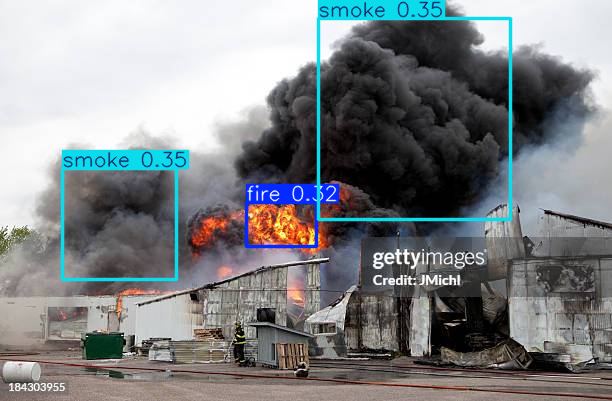

In [ ]:
from PIL import Image

model = YOLO("/content/runs/detect/train/weights/best.pt")

result = model("/gettyimages-184303955-612x612.jpg", save=True, conf=0.25)

result[0].show()

**Subtask 2:** Object Counting in Video Using YOLO

### Environment Preparation

- Ultralytics: Used to load YOLO models and perform object detection and tracking.
- OpenCV: Used to read, process, and write video frames.
- YOLO Solutions: Provides the ObjectCounter tool to count objects crossing a defined line.

OpenCV is important because videos consist of multiple frames that must be processed individually.

A pretrained YOLO model can detect common objects without requiring us to train a new model.

Object tracking means following the same object across multiple video frames while maintaining its identity.

In [ ]:
!pip install ultralytics opencv-python

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO, solutions
import cv2
import os
import matplotlib.pyplot as plt

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


### Step 2: Load a Pretrained YOLO Model

A pretrained model is a model that has already learned from
a large dataset.

COCO pretrained models are useful because they can detect
common objects such as cars, buses, trucks, persons, and bicycles.

Model class names represent the categories that the model
can recognize.

In [ ]:

import cv2
from ultralytics import solutions

# Load video
video_path = "/content/vecteezy_traffic-surveillance-camera-overlooking-a-busy-multilane_62264575.mp4"

cap = cv2.VideoCapture(video_path)
assert cap.isOpened(), "Error reading video file"

# Get video properties
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

print("Width:", w)
print("Height:", h)
print("FPS:", fps)

# Define counting line using two points
region_points = [
    (int(w * 0.25), int(h * 0.80)),
    (int(w * 0.92), int(h * 0.80))
]

# Create output video
video_writer = cv2.VideoWriter(
    "/content/object_counting_final.mp4",
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (w, h)
)

# Initialize Object Counter
counter = solutions.ObjectCounter(
    show=False,
    region=region_points,
    model="yolo26n.pt",
    classes=[2, 5, 7],
    tracker="bytetrack.yaml"
)

# Process video frame by frame
while cap.isOpened():

    success, im0 = cap.read()

    if not success:
        print("Video processing completed.")
        break

    results = counter(im0)

    video_writer.write(results.plot_im)

# Release resources
cap.release()
video_writer.release()
cv2.destroyAllWindows()

# Display counting results
print("Cars, Buses, and Trucks Counting Results:")
print("IN:", counter.in_count)
print("OUT:", counter.out_count)

print("Final video saved successfully!")


Width: 2560
Height: 1440
FPS: 24.0
Ultralytics Solutions: ✅ {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': [(640, 1152), (2355, 1152)], 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'bytetrack.yaml', 'verbose': True, 'data': 'images', 'recognizer': 'paddleocr'}
0: 640x640 3.3ms, 6 car
Speed: 195.4ms track, 3.3ms solution per image at shape (1, 3, 640, 640)

1: 640x640 1.9ms, 5 car
Speed: 31.1ms track, 1.9ms solution per image at shape (1, 3, 640, 640)

2: 640x640 1.8ms, 5 car
Spe

### Step 3: Load a Traffic Video

OpenCV is used to load the traffic video.

FPS (Frames Per Second) represents the number of frames
displayed or processed per second.

Frame width and height are needed to create the output video
with the same dimensions as the input video.

Checking whether the video opened successfully prevents
processing errors.

### Step 4: Define the Counting Line

A counting line is a virtual line placed inside the video frame.
Objects are counted when they cross this line.

The line is represented by two points:
Point 1 (x1, y1) and Point 2 (x2, y2).

The position of the counting line affects the counting result.
It should be placed where vehicles clearly pass through it
to improve counting accuracy.

### Step 5: Track and Count Objects

The video is processed frame by frame.

Object detection identifies objects in each frame,
while object tracking follows the same objects across frames.

Object IDs help distinguish individual objects and prevent
counting the same object multiple times.

The persist=True argument is useful in YOLO tracking because
it maintains tracking information between consecutive frames.

Ultralytics ObjectCounter manages tracking internally
while updating the counting results.

In [ ]:

import cv2
from ultralytics import solutions

# Input video
video_path = "/content/vecteezy_traffic-surveillance-camera-overlooking-a-busy-multilane_62264575.mp4"

cap = cv2.VideoCapture(video_path)

assert cap.isOpened(), "Error reading video file"

# Video information
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

if fps <= 0:
    fps = 24

# Counting region
region_points = [
    (int(w * 0.25), int(h * 0.76)),
    (int(w * 0.92), int(h * 0.76)),
    (int(w * 0.92), int(h * 0.86)),
    (int(w * 0.25), int(h * 0.86))
]

# Output video
output_path = "/content/object_counting_final.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
video_writer = cv2.VideoWriter(output_path, fourcc, fps, (w, h))

assert video_writer.isOpened(), "Error creating output video"

# YOLO Object Counter
counter = solutions.ObjectCounter(
    show=False,
    region=region_points,
    model="yolo26n.pt",
    classes=[2, 5, 7],  # Car, Bus, Truck
    tracker="bytetrack.yaml"
)

while cap.isOpened():

    success, im0 = cap.read()

    if not success:
        break

    # Run object counting
    results = counter(im0)

    # Get annotated frame
    frame = results.plot_im.copy()

    # Get IN and OUT counts
    in_count = getattr(counter, "in_count", 0)
    out_count = getattr(counter, "out_count", 0)

    # Large counting panel
    panel_x = w - 430
    panel_y = 40

    overlay = frame.copy()

    cv2.rectangle(
        overlay,
        (panel_x, panel_y),
        (w - 30, panel_y + 170),
        (25, 25, 25),
        -1
    )

    # Transparent background
    frame = cv2.addWeighted(overlay, 0.75, frame, 0.25, 0)

    # Panel title
    cv2.putText(
        frame,
        "VEHICLE COUNTING",
        (panel_x + 20, panel_y + 38),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (255, 255, 255),
        2
    )

    # IN count
    cv2.putText(
        frame,
        f"IN: {in_count}",
        (panel_x + 20, panel_y + 88),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.1,
        (0, 255, 0),
        3
    )

    # OUT count
    cv2.putText(
        frame,
        f"OUT: {out_count}",
        (panel_x + 20, panel_y + 140),
        cv2.FONT_HERSHEY_SIMPLEX,
        1.1,
        (0, 165, 255),
        3
    )

    # Save frame
    video_writer.write(frame)

# Release resources
cap.release()
video_writer.release()

print("Video processing completed!")
print("Output saved to:", output_path)


Ultralytics Solutions: ✅ {'source': None, 'model': 'yolo26n.pt', 'classes': [2, 5, 7], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': [(640, 1094), (2355, 1094), (2355, 1238), (640, 1238)], 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (20, 20), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': False, 'iou': None, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'bytetrack.yaml', 'verbose': True, 'data': 'images', 'recognizer': 'paddleocr'}
0: 640x640 2.1ms, 6 car
Speed: 126.5ms track, 2.1ms solution per image at shape (1, 3, 640, 640)

1: 640x640 1.5ms, 5 car
Speed: 19.5ms track, 1.5ms solution per image at shape (1, 3, 640, 640)

2: 640x640 1.3ms, 5 car
Speed: 21.0

# Subtask 3: VisionEye Object Mapping Using YOLO

### Step 1: Prepare the Environment

In this task, we use Ultralytics YOLO and OpenCV to apply VisionEye object mapping to a video.

VisionEye is an Ultralytics solution that visualizes the relationship between detected objects and a selected observation point.

Unlike normal object detection, which mainly displays bounding boxes and class labels, VisionEye adds visual lines connecting detected objects to a specific viewpoint.

### Step 2: Load the Video File

First, we use OpenCV to load the input video using `cv2.VideoCapture()`.

We check whether the video is opened successfully before processing it.

We also extract the video's width, height, and FPS to configure the output video correctly.

**Why are these properties important?**

- Video quality affects object detection accuracy.
- Frame width and height determine the output resolution.
- FPS helps maintain the original video's playback speed.
- Poor lighting, low resolution, or blurry frames may reduce detection accuracy.

### Step 3: Initialize VisionEye

We initialize VisionEye using the pretrained `yolo26n.pt` model.

The selected class is:

- Class 0: Person

We use `classes=[0]` to detect people only and ignore other object categories.

This makes the output more focused and easier to analyze.

We also set the observation point to `(50, 50)`, which determines the point toward which the VisionEye visualization is directed.

The `show=True` parameter enables displaying the processed output.

### Step 4: Process the Video Frame by Frame

The video is processed frame by frame using an OpenCV loop.

For each frame:

1. Read the next frame from the input video.
2. Pass the frame to the VisionEye solution.
3. Detect people in the frame.
4. Generate the VisionEye visualization.
5. Write the processed frame into the output video.

The `results.plot_im` property is used to obtain the visualized frame before saving it.

This process continues until all video frames have been processed.

### Step 5: Save the Output Video

After processing is completed, we release the video capture and video writer resources.

The processed video is saved as:

`visioneye_output.mp4`

The output video contains:
- Detected people.
- Object detection bounding boxes and labels.
- VisionEye visualization lines directed toward the selected observation point.

### Conclusion

In this task, we applied YOLO VisionEye to a video containing people using the pretrained YOLO model.

By selecting the Person class and defining an observation point, we visualized the relationship between detected people and the selected viewpoint.

This technique can be useful in people monitoring and visual observation systems.

In [ ]:
import cv2

from ultralytics import solutions

cap = cv2.VideoCapture("/content/giffffffffff.mp4")
assert cap.isOpened(), "Error reading video file"

# Video writer
w, h, fps = (int(cap.get(x)) for x in (cv2.CAP_PROP_FRAME_WIDTH, cv2.CAP_PROP_FRAME_HEIGHT, cv2.CAP_PROP_FPS))
video_writer = cv2.VideoWriter("visioneye_output.mp4", cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

# Initialize vision eye object
visioneye = solutions.VisionEye(
    show=True,  # display the output
    model="yolo26n.pt",  # use any model that Ultralytics supports, e.g., yolo26s.pt
    classes=[0, 2],  # generate visioneye view for specific classes
    vision_point=(50, 50),  # the point where VisionEye will view objects and draw tracks
)

# Process video
while cap.isOpened():
    success, im0 = cap.read()

    if not success:
        print("Video frame is empty or video processing has been successfully completed.")
        break

    results = visioneye(im0)

    print(results)  # access the output

    video_writer.write(results.plot_im)  # write the video file

cap.release()
video_writer.release()
cv2.destroyAllWindows()  # destroy all opened windows

Ultralytics Solutions: ✅ {'source': None, 'model': 'yolo26n.pt', 'classes': [0, 2], 'show_conf': True, 'show_labels': True, 'show_boxes': True, 'region': None, 'colormap': 21, 'show_in': True, 'show_out': True, 'up_angle': 145.0, 'down_angle': 90.0, 'kpts': [6, 8, 10], 'analytics_type': 'line', 'figsize': (12.8, 7.2), 'blur_ratio': 0.5, 'vision_point': (50, 50), 'crop_dir': 'cropped-detections', 'json_file': None, 'line_width': 2, 'records': 5, 'fps': 30.0, 'max_hist': 5, 'meter_per_pixel': 0.05, 'max_speed': 120, 'show': True, 'iou': None, 'conf': 0.25, 'device': None, 'max_det': 300, 'quantize': None, 'imgsz': 640, 'tracker': 'tracktrack.yaml', 'verbose': True, 'data': 'images', 'recognizer': 'paddleocr'}
WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 866ms
Prepared 1 package in 455ms
Installed 1 package 

**Subtask 4:** Custom Object Detection on the Neural Ocean Dataset

### Step 1: Download the Dataset

In this step, we download the Neural Ocean dataset from Roboflow.

The dataset will be used to train a custom YOLO object detection model. It contains images with annotations that identify the objects and their locations.

**Dataset Information:**
- Workspace: neural-ocean
- Project: neural_ocean
- Version: 3
- Format: YOLO

After downloading, the dataset will contain images and corresponding annotation files organized into training, validation, and testing folders.

The `data.yaml` file contains important dataset information, including the dataset paths and object class names.

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="jtCJlEUyRZ2yTvQ0IUw2")
project = rf.workspace("neural-ocean").project("neural_ocean")
version = project.version(3)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Neural_Ocean-3 in yolo26:: 100%|██████████| 10266/10266 [00:01<00:00, 7209.58it/s]


In [ ]:
from IPython.display import display, Markdown

display(Markdown(f"""
### Dataset Information

- **Workspace Name:** neural-ocean
- **Project Name:** neural_ocean
- **Dataset Version:** 3
- **Dataset Location:** `{dataset.location}`
"""))


### Dataset Information

- **Workspace Name:** neural-ocean
- **Project Name:** neural_ocean
- **Dataset Version:** 3
- **Dataset Location:** `/content/Neural_Ocean-3`


In [ ]:
import yaml
import os

yaml_path = os.path.join(dataset.location, "data.yaml")

with open(yaml_path, "r") as file:
    data = yaml.safe_load(file)

print("Number of Classes:", data["nc"])
print("Class Names:", data["names"])

Number of Classes: 15
Class Names: ['Mask', 'can', 'cellphone', 'electronics', 'gbottle', 'glove', 'metal', 'misc', 'net', 'pbag', 'pbottle', 'plastic', 'rod', 'sunglasses', 'tire']


**1. What is the dataset used for?**

The Neural Ocean dataset is used to train a custom YOLO object detection model. It contains images with annotations that help the model learn how to recognize and locate specific objects.

**2. What classes exist in the dataset?**

The dataset contains 15 classes:

- Class Names: ['Mask', 'can', 'cellphone', 'electronics', 'gbottle', 'glove', 'metal', 'misc', 'net', 'pbag', 'pbottle', 'plastic', 'rod', 'sunglasses', 'tire']


Each class represents a specific object category that the YOLO model will learn to detect.

**3. How is the dataset organized after download?**

After downloading the dataset from Roboflow in YOLO format, it is organized into the following structure:

- **train:** Contains images used to train the model.
- **valid:** Contains images used to evaluate the model during training.
- **test:** Contains images used for final testing.
- **data.yaml:** Contains dataset information, including the paths to the image folders, number of classes, and class names.

Each image has a corresponding annotation file containing the object class and bounding box coordinates.

This organization allows YOLO to load the images and their annotations correctly during training and evaluation.

### Step 2: Train a Custom YOLO Model

In this step, we train a custom YOLO model using the downloaded Neural Ocean dataset.

We use a YOLO nano model because it is lightweight, requires fewer computational resources, and provides a good starting point for custom object detection.

**Training Parameters:**

- **Task:** Object Detection
- **Model:** YOLO26n
- **Epochs:** 60
- **Image Size:** 832
- **Optimizer:** SGD
- **Learning Rate:** 0.001
- **Patience:** 10


In [ ]:
!yolo task = detect mode=train model=yolo26n.pt data={dataset.location}/data.yaml epochs=60 patience=10 imgsz=832 optimizer="SGD"  lr0=0.001

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Neural_Ocean-3/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=832, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, o

**Why do training parameters matter?**

Training parameters control how the model learns from the dataset and affect its performance and training time.

**What does image size affect?**

Image size determines the dimensions used to process images during training. A larger image size may help detect smaller objects but requires more memory and processing power.

**Why is patience used?**

Patience controls how long training continues without improvement in validation performance. It helps stop training when the model is no longer improving.

**How do optimizer and learning rate affect training?**

The optimizer updates the model's weights during training. The learning rate controls the size of these updates. A suitable learning rate helps the model learn effectively without making excessively large updates.

### Step 3: Inspect the Trained Weights

After completing the training process, YOLO automatically saves the trained model weights in the `weights` folder.

The two main files are:

- **best.pt:** Contains the model weights from the epoch that achieved the best validation performance.
- **last.pt:** Contains the model weights from the final training epoch.

**Which file should be used for final prediction?**

The `best.pt` file should be used for final predictions because it represents the model's best performance during validation, rather than simply the last training epoch.

**Why is saving model weights important?**

Saving model weights is important because it preserves what the model has learned during training. This prevents losing the training progress and allows the trained model to be used later.

**How can weights be reused without retraining?**

The saved weights can be loaded directly using the YOLO class. This allows us to perform object detection on new images or videos without repeating the training process.

For example:

```python
from ultralytics import YOLO

model = YOLO("runs/detect/train/weights/best.pt")
```

This loads the trained model and makes it ready for future predictions.

In [ ]:
import os

weights_path = "runs/detect/train/weights"

print("Best.pt:", os.path.exists(weights_path + "/best.pt"))
print("Last.pt:", os.path.exists(weights_path + "/last.pt"))

Best.pt: True
Last.pt: True


### Step 4: Test the Model on New Images

In this step, we test the trained YOLO model on multiple unseen images to evaluate its ability to detect objects outside the training dataset.

We use the trained `best.pt` weights to make predictions on new images.

For each image, we:
1. Load the trained model.
2. Run object detection.
3. Save the prediction result.
4. Display the annotated image.
5. Check whether the detected objects and labels are correct.

Testing on unseen images helps us understand how well the model generalizes to new examples.


image 1/1 /content/10.webp: 480x832 1 cellphone, 17.5ms
Speed: 2.8ms preprocess, 17.5ms inference, 2.4ms postprocess per image at shape (1, 3, 480, 832)
Results saved to /content/runs/detect/predict
Detected objects: 1 cellphone, 


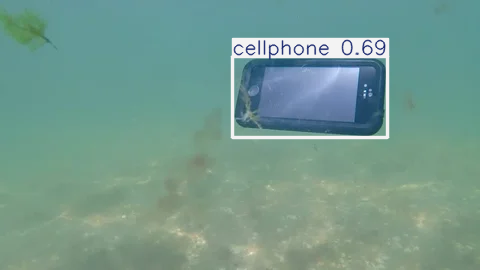

In [ ]:
from ultralytics import YOLO
from IPython.display import display
from PIL import Image

# Load trained model
model = YOLO("runs/detect/train/weights/best.pt")

# Image path
image_path = "/content/10.webp"

# Run prediction
results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=832,
    save=True
)

# Display result
for result in results:
    print("Detected objects:", result.verbose())

    display(Image.fromarray(result.plot()[:, :, ::-1]))

### Confidence Threshold

The confidence threshold is the minimum confidence score required for a detection to be displayed.

For example, when using `conf=0.25`, detections with confidence scores below 25% are ignored.

- A higher threshold produces fewer detections but generally removes more uncertain predictions.
- A lower threshold allows more detections but may also produce incorrect predictions.

We use a confidence threshold of 0.25 as a starting point for testing.

### Why Some Images May Fail Detection

Some images may not produce correct detections for several reasons:

- **Different backgrounds:** New images may contain backgrounds that the model did not see during training.
- **Image quality:** Blurry or low-resolution images can make objects difficult to recognize.
- **Object size:** Very small or partially hidden objects may be missed.
- **Different appearance:** Objects with unusual shapes, colors, or lighting conditions may be difficult to detect.
- **Confidence threshold:** Some correct detections may be ignored if their confidence scores are below the selected threshold.

### Why Is Testing on Unseen Images Important?

Testing on unseen images is important because it helps evaluate the model's ability to generalize to new data.

It shows whether the model has learned useful object features instead of simply memorizing the training images.

It also helps identify detection errors and areas that need improvement.

## Step 5: Download the Trained Model

After completing the training process, the trained model weights are saved as `best.pt` and `last.pt`. Both files should be downloaded and stored for future use.

### Which File Is Better for Deployment?

The **`best.pt`** file is better for deployment because it contains the model weights from the epoch that achieved the best validation performance.

### Why Is `best.pt` Usually Preferred?

- It represents the model's best performance during training.
- It is selected based on validation results.
- It is generally expected to provide better predictions on unseen images than `last.pt`.
- `last.pt` contains the weights from the final training epoch and is mainly useful for resuming training.

### How Can the Model Be Used Later?

The saved weights can be reused in another Google Colab notebook or Python application without training the model again.

First, upload or copy the `best.pt` file into the new environment, then load it using Ultralytics:

```python
from ultralytics import YOLO

model = YOLO("best.pt")
```

You can then use the model to detect objects in new images:

```python
results = model.predict(
    source="test_image.jpg",
    conf=0.25,
    save=True
)
```

### Download the Model Weights

Both files can be downloaded directly from Google Colab:

```python
from google.colab import files

files.download("runs/detect/train/weights/best.pt")
files.download("runs/detect/train/weights/last.pt")
```

**Conclusion:** Both weight files should be saved, but `best.pt` is the recommended file for final predictions and deployment because it represents the best validation performance achieved during training.